# Q1 — Les liaisons les moins fiables du réseau

**Question** : quelles sont les liaisons TGV les moins fiables du réseau, et
cette instabilité s'aggrave-t-elle ou s'améliore-t-elle dans le temps ?

Le notebook suit `notebook_example.ipynb` : paramètres lus dans
`config/defaut.yaml` (section `liaisons_fiabilite`), données lues par
`lire_donnees` puis `nettoyer_regularite`, calculs repris de
`railinsight.analysis.reliability` (le même code que l'application). Voir
`DATASHEET.md` pour la documentation du jeu de données et ses limites.

## Définition de la métrique de fiabilité

Pour une liaison donnée sur un mois donné :

$$
\text{taux d'incidents} = \frac{\text{trains annulés} + \text{trains en retard} > 15\text{min à l'arrivée}}{\text{circulations prévues}}
$$

- Un train **annulé** ou **en retard de plus de 15 minutes à l'arrivée** est
  considéré comme un incident de fiabilité (seuil couramment utilisé par la SNCF
  pour ses propres indicateurs de ponctualité).
- Le taux est agrégé par liaison sur l'ensemble de la période pour le classement
  global, puis calculé mois par mois pour étudier la tendance temporelle (pente
  d'une régression linéaire simple sur le taux mensuel).
- Les lignes où `Nombre de circulations prévues` vaut 0 sont exclues du calcul du
  taux (73 lignes dans le jeu de données, voir `DATASHEET.md`) pour éviter une
  division par zéro.


## 1. Charger la configuration

`charger_config()` lit `config/defaut.yaml`, vérifie toutes les valeurs, puis renvoie un objet `cfg`. Si une valeur est invalide, une erreur `ConfigInvalide` indique la clé en cause.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from railinsight.config import charger_config

cfg = charger_config()
p = cfg.liaisons_fiabilite

COVID_DEBUT = pd.Period(p.covid_debut, freq="M")  # exclu de la pente uniquement
COVID_FIN = pd.Period(p.covid_fin, freq="M")
TOP_N = p.top_n

GRAINE = cfg.graine  # graine commune à tout le projet

print("fenêtre COVID :", COVID_DEBUT, "->", COVID_FIN)
print("top_n :", TOP_N)

fenêtre COVID : 2020-03 -> 2021-06
top_n : 10


## 2. Charger et nettoyer les données

`lire_donnees` contrôle le schéma et renomme les colonnes (`prevus`, `annules`, `retards_sup_15min`…). `nettoyer_regularite` applique les règles communes du projet sans supprimer de ligne.

In [2]:
from railinsight.analysis.donnees import lire_donnees
from railinsight.analysis.nettoyage import nettoyer_regularite

data = nettoyer_regularite(lire_donnees(cfg.chemins.donnees))

print(data.shape)
data.head()

42 ligne(s) en double sur (mois, gare_depart, gare_arrivee), conservées


(12907, 30)


,date,service,gare_depart,gare_arrivee,duree_moyenne,prevus,annules,retards_depart,retard_moyen_retardes_depart,retard_moyen_depart,...,prct_cause_materiel,prct_cause_gare,prct_cause_voyageurs,mois,gare_a,gare_b,liaison,circules,minutes_retard,circules_mesures
0,2018-01-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141.0,870.0,5.0,289.0,11.247809,3.693179,...,15.966387,5.042017,0.840336,2018-01,BORDEAUX ST JEAN,PARIS MONTPARNASSE,BORDEAUX ST JEAN - PARIS MONTPARNASSE,865.0,5632.116667,865.0
1,2018-01-01,National,LE MANS,PARIS MONTPARNASSE,56.0,406.0,1.0,213.0,8.479969,4.567119,...,16.666667,8.333333,3.333333,2018-01,LE MANS,PARIS MONTPARNASSE,LE MANS - PARIS MONTPARNASSE,405.0,2172.233333,405.0
2,2018-01-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166.0,226.0,0.0,21.0,6.239683,0.286283,...,16.666667,5.555556,11.111111,2018-01,LA ROCHELLE VILLE,PARIS MONTPARNASSE,LA ROCHELLE VILLE - PARIS MONTPARNASSE,226.0,664.000000,226.0
3,2018-01-01,National,PARIS MONTPARNASSE,NANTES,124.0,508.0,3.0,71.0,7.235211,0.734290,...,20.370370,5.555556,1.851852,2018-01,NANTES,PARIS MONTPARNASSE,NANTES - PARIS MONTPARNASSE,505.0,2672.566667,505.0
4,2018-01-01,National,POITIERS,PARIS MONTPARNASSE,94.0,472.0,4.0,224.0,6.784673,3.229701,...,15.789474,1.754386,1.754386,2018-01,PARIS MONTPARNASSE,POITIERS,PARIS MONTPARNASSE - POITIERS,468.0,2284.950000,468.0


In [3]:
colonnes_q1 = ["prevus", "annules", "retards_sup_15min"]

print("--- Statistiques descriptives ---")
print(data[colonnes_q1].describe())
print("\n--- Valeurs manquantes ---")
print(data[colonnes_q1].isna().sum())
print("\n--- Lignes sans train prévu ---")
print((data["prevus"] == 0).sum())
print("\n--- Doublons sur (mois, gare_depart, gare_arrivee) ---")
print(data.duplicated(["mois", "gare_depart", "gare_arrivee"]).sum())

--- Statistiques descriptives ---
             prevus       annules  retards_sup_15min
count  12907.000000  12907.000000       12907.000000
mean     273.443635      8.273650          28.101418
std      184.117868     21.805356          23.911428
min        0.000000      0.000000           0.000000
25%      151.000000      0.000000          11.000000
50%      231.000000      2.000000          22.000000
75%      365.000000      7.000000          38.000000
max     1104.000000    297.000000         312.000000

--- Valeurs manquantes ---
prevus               0
annules              0
retards_sup_15min    0
dtype: int64

--- Lignes sans train prévu ---
73

--- Doublons sur (mois, gare_depart, gare_arrivee) ---
42


## 3. Classement et tendance

In [4]:
from railinsight.analysis.reliability import (
    build_route_incidents,
    compute_monthly_rates,
    compute_trend_slopes,
    rank_routes,
)

# retire les lignes sans train prévu (retirer_sans_train), puis calcule le taux
work = build_route_incidents(data)
work.head()

,route,date,planned,cancelled,late15,incidents,rate,month
0,BORDEAUX ST JEAN → PARIS MONTPARNASSE,2018-01-01,870.0,5.0,110.0,115.0,0.132184,2018-01
1,LE MANS → PARIS MONTPARNASSE,2018-01-01,406.0,1.0,32.0,33.0,0.081281,2018-01
2,PARIS MONTPARNASSE → LA ROCHELLE VILLE,2018-01-01,226.0,0.0,11.0,11.0,0.048673,2018-01
3,PARIS MONTPARNASSE → NANTES,2018-01-01,508.0,3.0,39.0,42.0,0.082677,2018-01
4,POITIERS → PARIS MONTPARNASSE,2018-01-01,472.0,4.0,42.0,46.0,0.097458,2018-01


In [5]:
# Classement global : liaisons les moins fiables sur toute la période
worst_routes = rank_routes(work, top_n=TOP_N)
worst_routes

,planned,incidents,rate
route,,,
ITALIE → PARIS LYON,7208.0,2592.0,0.359600
MADRID → MARSEILLE ST CHARLES,929.0,242.0,0.260495
PARIS EST → STUTTGART,12798.0,3317.0,0.259181
LYON PART DIEU → LILLE,30165.0,7661.0,0.253970
CHAMBERY CHALLES LES EAUX → PARIS LYON,22528.0,5625.0,0.249689
MARSEILLE ST CHARLES → LILLE,20074.0,4959.0,0.247036
PARIS EST → FRANCFORT,15855.0,3695.0,0.233050
MACON LOCHE → PARIS LYON,23058.0,5253.0,0.227817
ANNECY → PARIS LYON,14678.0,3322.0,0.226325


In [ ]:
# Taux mensuel par liaison + pente de tendance (régression linéaire simple).
# La fenêtre COVID reste dans `monthly` pour l'affichage, mais est exclue de la pente.
monthly = compute_monthly_rates(work)
trends = compute_trend_slopes(monthly, p.covid_debut, p.covid_fin)

evolution = worst_routes.join(trends)
evolution["tendance"] = np.where(evolution["slope"] > 0, "se dégrade", "s'améliore")
evolution

,planned,incidents,rate,slope,tendance
route,,,,,
ITALIE → PARIS LYON,7208,2592,0.359600,-0.000515,s'améliore
MADRID → MARSEILLE ST CHARLES,929,242,0.260495,-0.001566,s'améliore
PARIS EST → STUTTGART,12798,3317,0.259181,0.004291,se dégrade
LYON PART DIEU → LILLE,30165,7661,0.253970,-0.000855,s'améliore
CHAMBERY CHALLES LES EAUX → PARIS LYON,22528,5625,0.249689,-0.000765,s'améliore
MARSEILLE ST CHARLES → LILLE,20074,4959,0.247036,-0.000746,s'améliore
PARIS EST → FRANCFORT,15855,3695,0.233050,0.001709,se dégrade
MACON LOCHE → PARIS LYON,23058,5253,0.227817,0.000247,se dégrade
ANNECY → PARIS LYON,14678,3322,0.226325,-0.000831,s'améliore


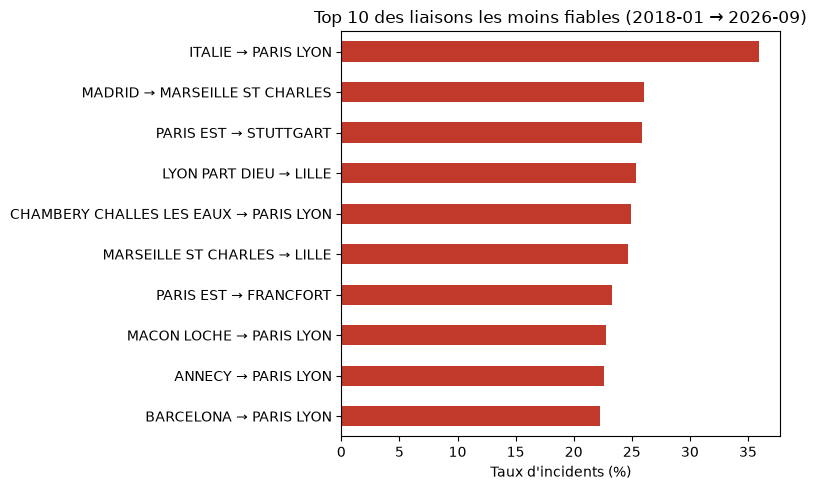

In [ ]:
# Visualisation : classement des liaisons les moins fiables
periode = f"{data['mois'].min()} → {data['mois'].max()}"
fig, ax = plt.subplots(figsize=(8, 5))
worst_routes["rate"].sort_values().mul(100).plot.barh(ax=ax, color="#c0392b")
ax.set_xlabel("Taux d'incidents (%)")
ax.set_ylabel("")
ax.set_title(f"Top {TOP_N} des liaisons les moins fiables ({periode})")
plt.tight_layout()
plt.show()

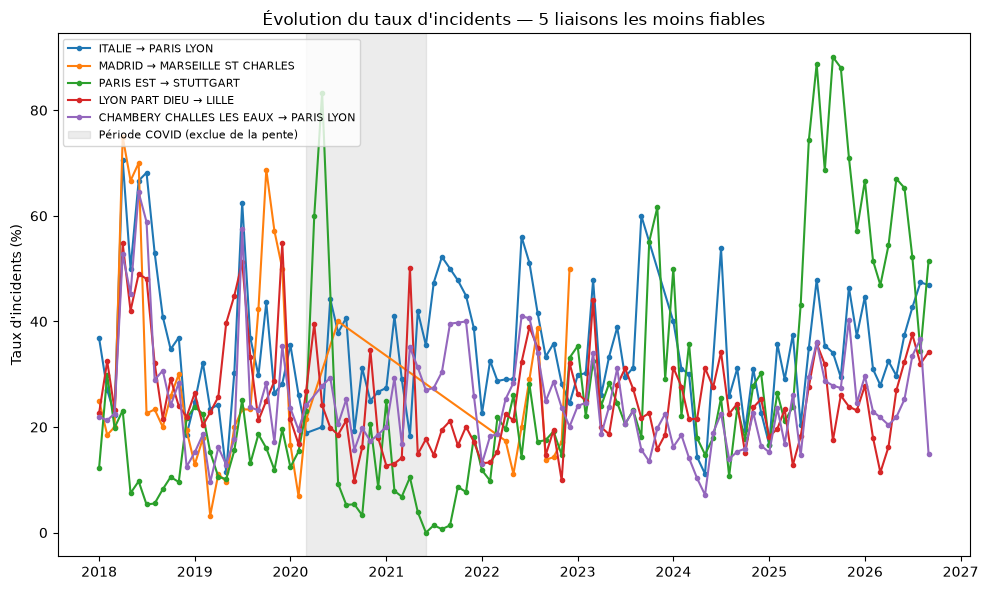

In [ ]:
# Visualisation : évolution mensuelle du taux d'incidents pour les pires liaisons
fig, ax = plt.subplots(figsize=(10, 6))
for route in worst_routes.index[:5]:
    serie = monthly[monthly["route"] == route].sort_values("month")
    ax.plot(
        serie["month"].dt.to_timestamp(),
        serie["rate"] * 100,
        marker="o",
        markersize=3,
        label=route,
    )
ax.axvspan(
    COVID_DEBUT.to_timestamp(),
    COVID_FIN.to_timestamp(),
    color="grey",
    alpha=0.15,
    label="Période COVID (exclue de la pente)",
)
ax.set_ylabel("Taux d'incidents (%)")
ax.set_title("Évolution du taux d'incidents — 5 liaisons les moins fiables")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## Pistes d'interprétation

- Les liaisons en tête du classement global sont-elles des liaisons à fort trafic
  (donc plus exposées statistiquement) ou réellement structurellement peu fiables
  (taux élevé indépendamment du volume) ?
- Parmi les liaisons les moins fiables, lesquelles ont une pente positive
  (dégradation) vs. négative (amélioration) sur la période ?
- La dégradation/amélioration est-elle concentrée sur quelques liaisons ou est-ce
  une tendance de réseau généralisée ?
- Les causes de retard (colonnes `Prct retard pour cause ...`) des liaisons qui se
  dégradent le plus sont-elles différentes de celles qui s'améliorent (ex. matériel
  roulant vs. infrastructure) ? À creuser dans une analyse complémentaire.

### Note méthodologique : période COVID

La période mars 2020 → juin 2021 (confinements et fort ralentissement du trafic)
est exclue du calcul de la **pente de tendance** car elle constitue un choc
exceptionnel et non structurel qui fausserait la mesure de dégradation/amélioration
de long terme. Elle reste visible (zone grisée) sur le graphique d'évolution pour
ne pas masquer cette période dans la lecture des données.